# Classification

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression

In [2]:
df=pd.read_csv('data/resumes_cleaned.csv').dropna(subset=['clean_text','label'])
df.shape

(962, 2)

In [4]:
print('total no of labels(jobs) :',df['label'].nunique())

total no of labels(jobs) : 25


## train test split

In [5]:
x_train,x_test,y_train,y_test=train_test_split(df['clean_text'],df['label'],test_size=0.2,random_state=42,stratify=df['label'])
vec=TfidfVectorizer(max_features=20000,ngram_range=(1,2),sublinear_tf=True)
Xtrain=vec.fit_transform(x_train); Xtest=vec.transform(x_test)
print('TF-IDF:',Xtrain.shape)

TF-IDF: (769, 20000)


## Training Classifiers

### Models

In [23]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression, RidgeClassifier, PassiveAggressiveClassifier
from sklearn.svm import LinearSVC
import seaborn as sns

In [6]:

def get_models():
    return {
        "Multinomial NB": MultinomialNB(),
        "Complement NB": ComplementNB(),
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Linear SVM": LinearSVC(),
        "Ridge Classifier": RidgeClassifier(),
        "Passive Aggressive": PassiveAggressiveClassifier(max_iter=1000, random_state=42),
    }


### Model Evalutation

In [8]:

def evaluate_model(model_name, y_true, y_pred):
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }
    return metrics
def plot_confusion_matrix(y_true, y_pred, model_name, labels=None, ax=None):
    cm = confusion_matrix(y_true, y_pred)
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"Confusion Matrix — {model_name}")
    return ax


def compare_models(results_list):
    return pd.DataFrame(results_list).sort_values("F1 Score", ascending=False).reset_index(drop=True)


In [12]:
results=[]
for name,model in get_models().items():
    model.fit(Xtrain,y_train); pred=model.predict(Xtest)
    results.append(evaluate_model(name,y_test,pred))

In [15]:
res_df=compare_models(results)
res_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Passive Aggressive,1.0000,1.0000,1.0000,1.0000
1,Linear SVM,1.0000,1.0000,1.0000,1.0000
2,Ridge Classifier,0.9948,0.9957,0.9948,0.9949
3,Complement NB,0.9948,0.9956,0.9948,0.9947
4,Logistic Regression,0.9896,0.9907,0.9896,0.9895
5,Multinomial NB,0.9534,0.9652,0.9534,0.9483


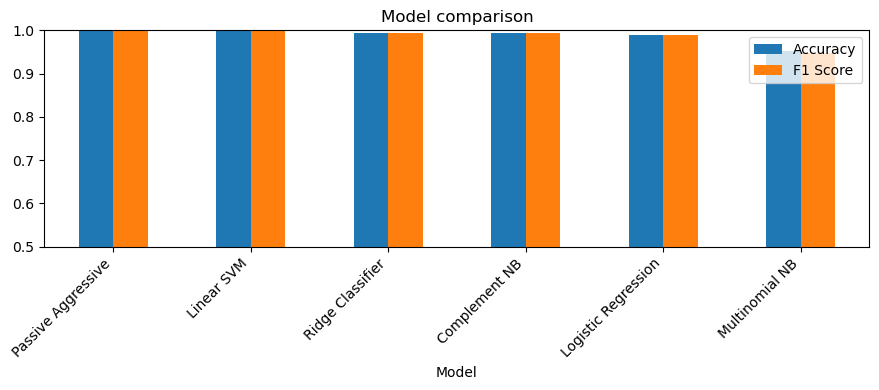

In [17]:
fig,ax=plt.subplots(figsize=(9,4))
res_df.set_index('Model')[['Accuracy','F1 Score']].plot(kind='bar',ax=ax)
ax.set_title('Model comparison')
ax.set_ylim(min(0.5,res_df['F1 Score'].min()-0.05),1.0)
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

### confusion matrix for the best model

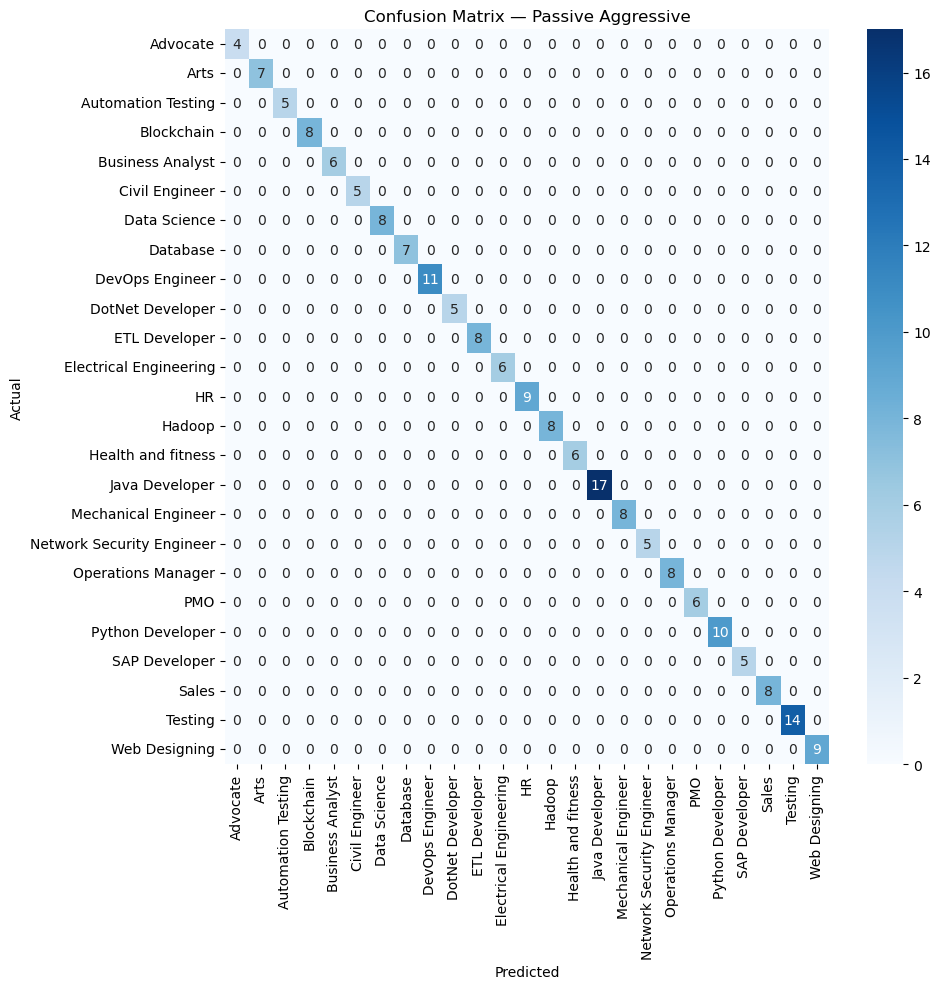

In [25]:
best_name=res_df.iloc[0]['Model']
best=get_models()[best_name]
best.fit(Xtrain,y_train) 
pred=best.predict(Xtest)
fig,ax=plt.subplots(figsize=(10,10))
plot_confusion_matrix(y_test,pred,best_name,labels=sorted(df['label'].unique()),ax=ax)
plt.tight_layout()
plt.show()

## Logistic Regression

In [28]:
gs=GridSearchCV(LogisticRegression(max_iter=1000),{'C':[0.1,1,10]},cv=3,scoring='f1_weighted',n_jobs=-1)
gs.fit(Xtrain,y_train)
tp=gs.best_estimator_.predict(Xtest)
print('best C:',gs.best_params_['C'])
print('tuned accuracy: %.4f'%accuracy_score(y_test,tp))
print('tuned weighted F1: %.4f'%f1_score(y_test,tp,average='weighted'))

best C: 10
tuned accuracy: 1.0000
tuned weighted F1: 1.0000


In [31]:
sample=x_test.iloc[0]
print('text :',str(sample)[:160])
print('true :',y_test.iloc[0])
print('pred :',best.predict(vec.transform([sample]))[0])

text : education details january bachelor engineering extc mumbai maharashtra mumbai university january diploma industrial electronics vashi maharashtra fr agnel polyt
true : ETL Developer
pred : ETL Developer
